In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries loaded successfully!")

All libraries loaded successfully!


In [2]:
df = sns.load_dataset("taxis")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print(df.head())

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


In [5]:
print(df.isnull().sum())


pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [6]:
df['payment'].fillna(df['payment'].mode()[0], inplace=True)

df['pickup_zone'].fillna(df['pickup_zone'].mode()[0], inplace=True)

df['pickup_borough'].fillna(df['pickup_borough'].mode()[0], inplace=True)

df['dropoff_zone'].fillna(df['dropoff_zone'].mode()[0], inplace=True)

df['dropoff_borough'].fillna(df['dropoff_borough'].mode()[0], inplace=True)

print("Missing values handled successfully!")

Missing values handled successfully!


C:\Users\HP\AppData\Local\Temp\ipykernel_45392\975455152.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df['payment'].fillna(df['payment'].mode()[0], inplace=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_45392\975455152.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained ass

In [7]:
df['payment'] = df['payment'].fillna(df['payment'].mode()[0])

df['pickup_zone'] = df['pickup_zone'].fillna(df['pickup_zone'].mode()[0])

df['pickup_borough'] = df['pickup_borough'].fillna(df['pickup_borough'].mode()[0])

df['dropoff_zone'] = df['dropoff_zone'].fillna(df['dropoff_zone'].mode()[0])

df['dropoff_borough'] = df['dropoff_borough'].fillna(df['dropoff_borough'].mode()[0])

print("Missing values handled successfully!")

Missing values handled successfully!


In [8]:
print(df.isnull().sum())


pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


In [9]:
df['pickup'] = pd.to_datetime(df['pickup'])
df['dropoff'] = pd.to_datetime(df['dropoff'])

print("Datetime conversion successful!")


Datetime conversion successful!


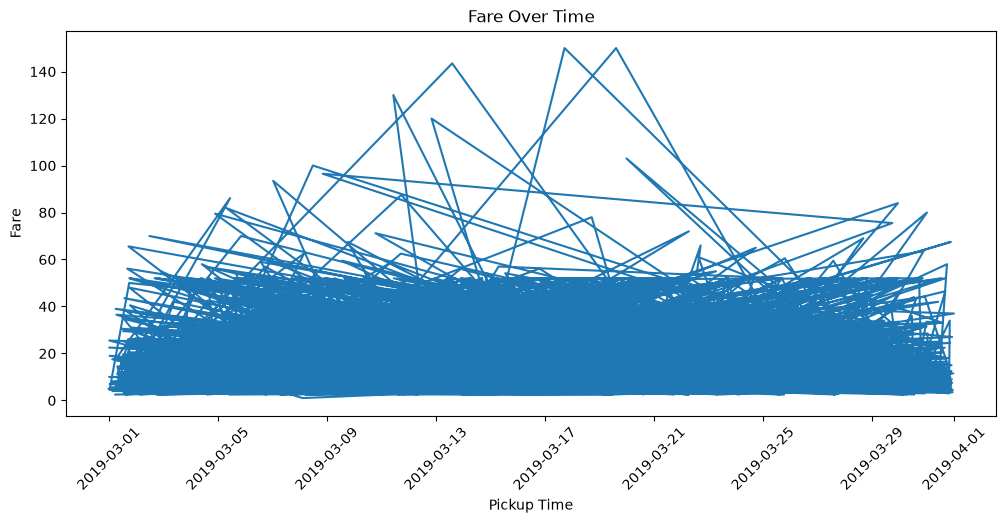

In [10]:
plt.figure(figsize=(12,5))

plt.plot(df['pickup'], df['fare'])

plt.title("Fare Over Time")
plt.xlabel("Pickup Time")
plt.ylabel("Fare")

plt.xticks(rotation=45)

plt.show()

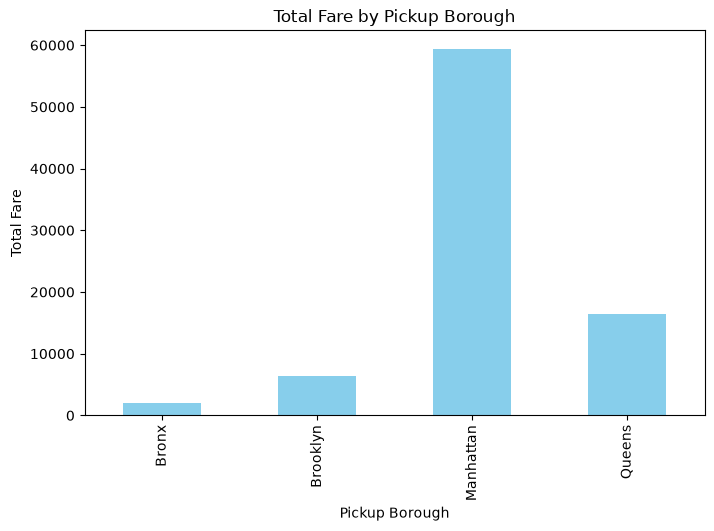

In [11]:
borough_fare = df.groupby('pickup_borough')['fare'].sum()

borough_fare.plot(
    kind='bar',
    figsize=(8,5),
    color='skyblue'
)

plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")

plt.show()

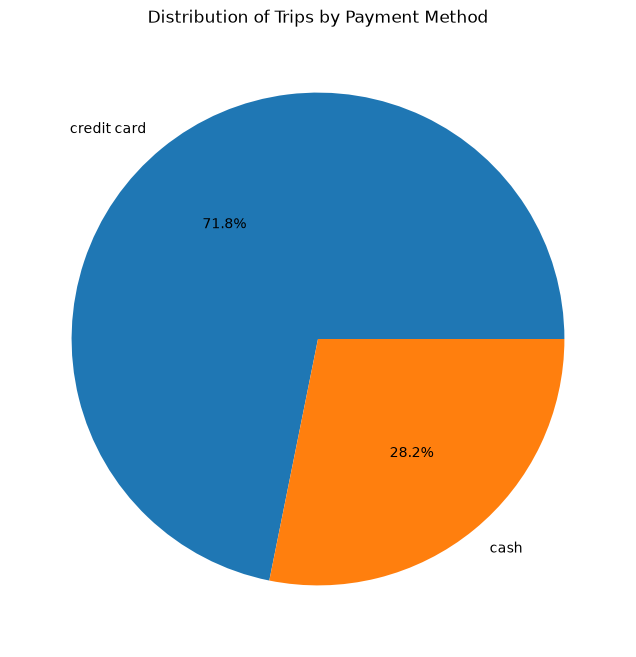

In [12]:
payment_counts = df['payment'].value_counts()

plt.figure(figsize=(8,8))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%'
)

plt.title("Distribution of Trips by Payment Method")

plt.show()

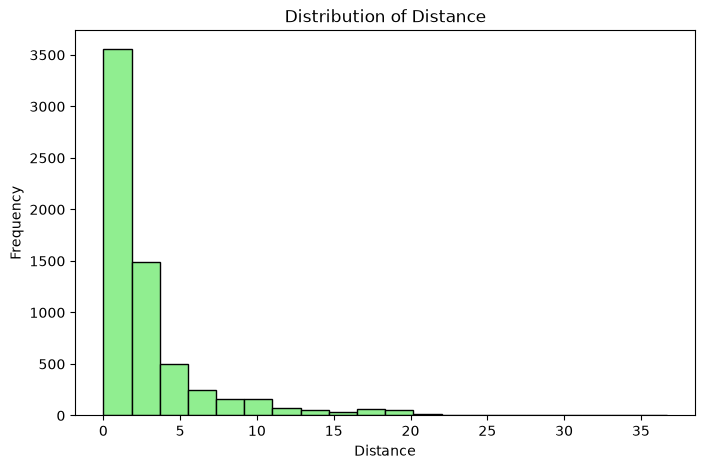

In [13]:
plt.figure(figsize=(8,5))

plt.hist(
    df['distance'],
    bins=20,
    color='lightgreen',
    edgecolor='black'
)

plt.title("Distribution of Distance")
plt.xlabel("Distance")
plt.ylabel("Frequency")

plt.show()

<Figure size 1000x500 with 0 Axes>

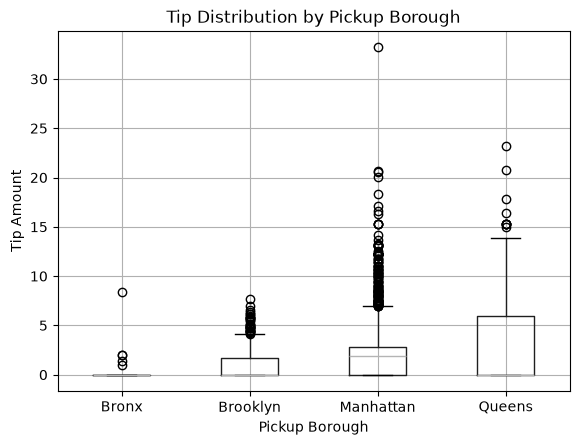

In [14]:
plt.figure(figsize=(10,5))

df.boxplot(
    column='tip',
    by='pickup_borough'
)

plt.title("Tip Distribution by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")

plt.suptitle('')

plt.show()

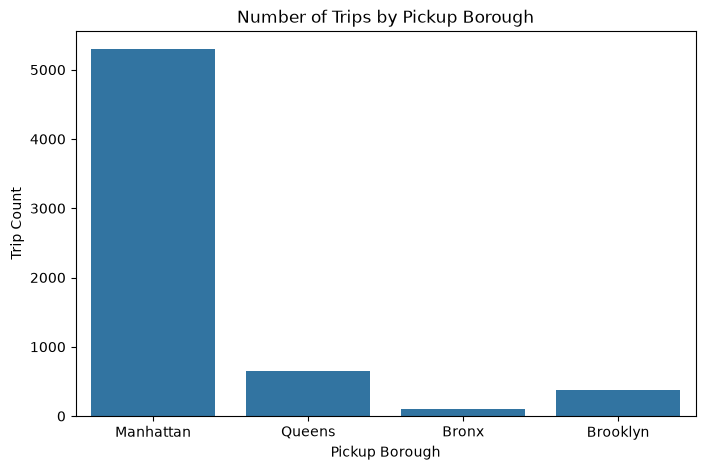

In [15]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='pickup_borough'
)

plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Trip Count")

plt.show()

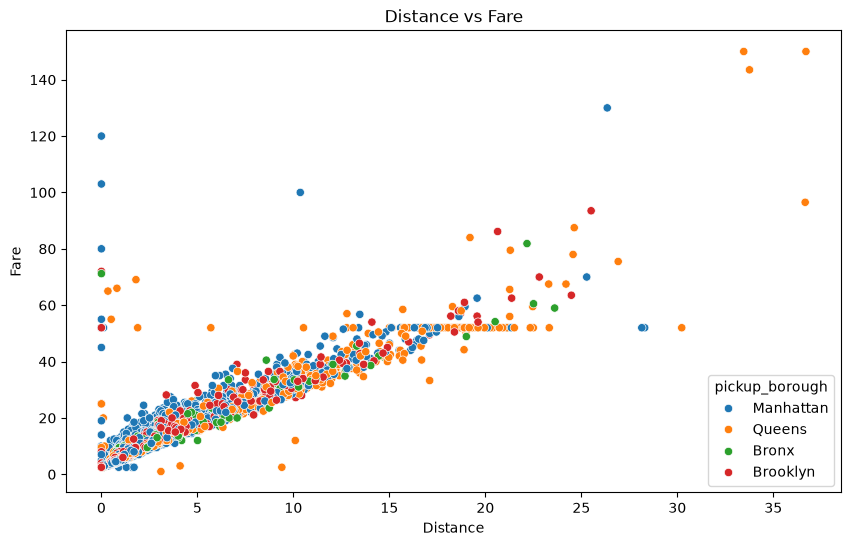

In [16]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough'
)

plt.title("Distance vs Fare")
plt.xlabel("Distance")
plt.ylabel("Fare")

plt.show()

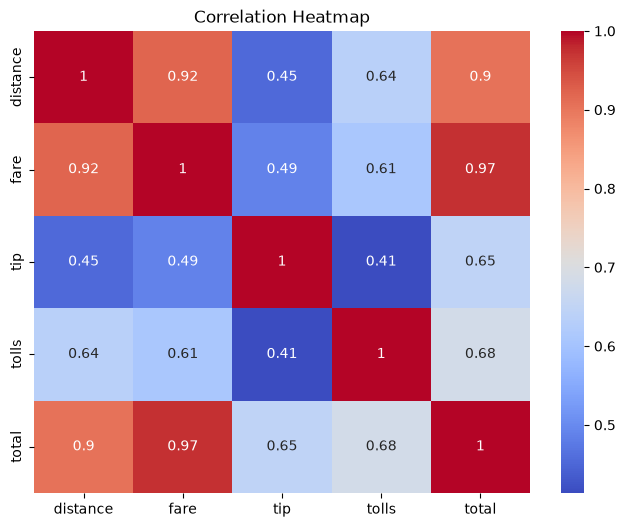

In [17]:
plt.figure(figsize=(8,6))

corr_matrix = df[['distance','fare','tip','tolls','total']].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.show()


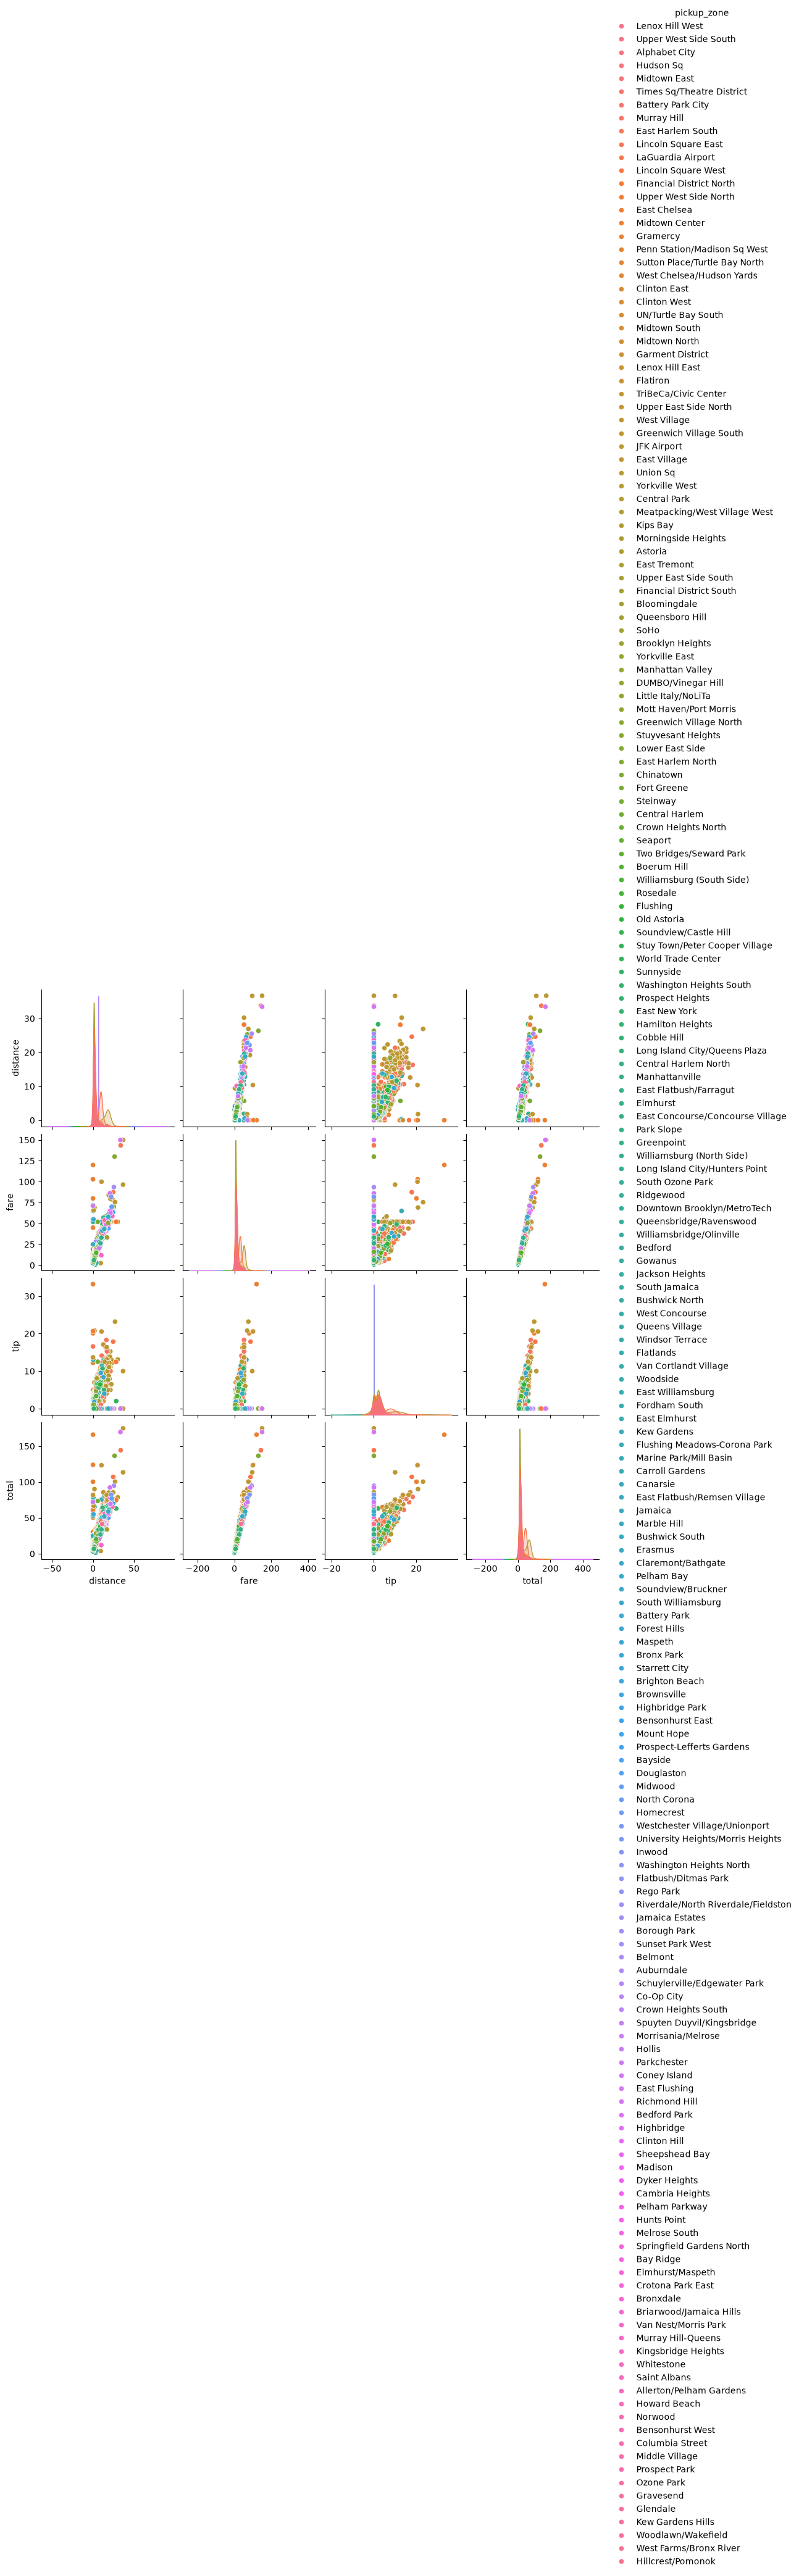

In [18]:
sns.pairplot(
    df[['distance', 'fare', 'tip', 'total', 'pickup_zone']],
    hue='pickup_zone'
)

plt.show()

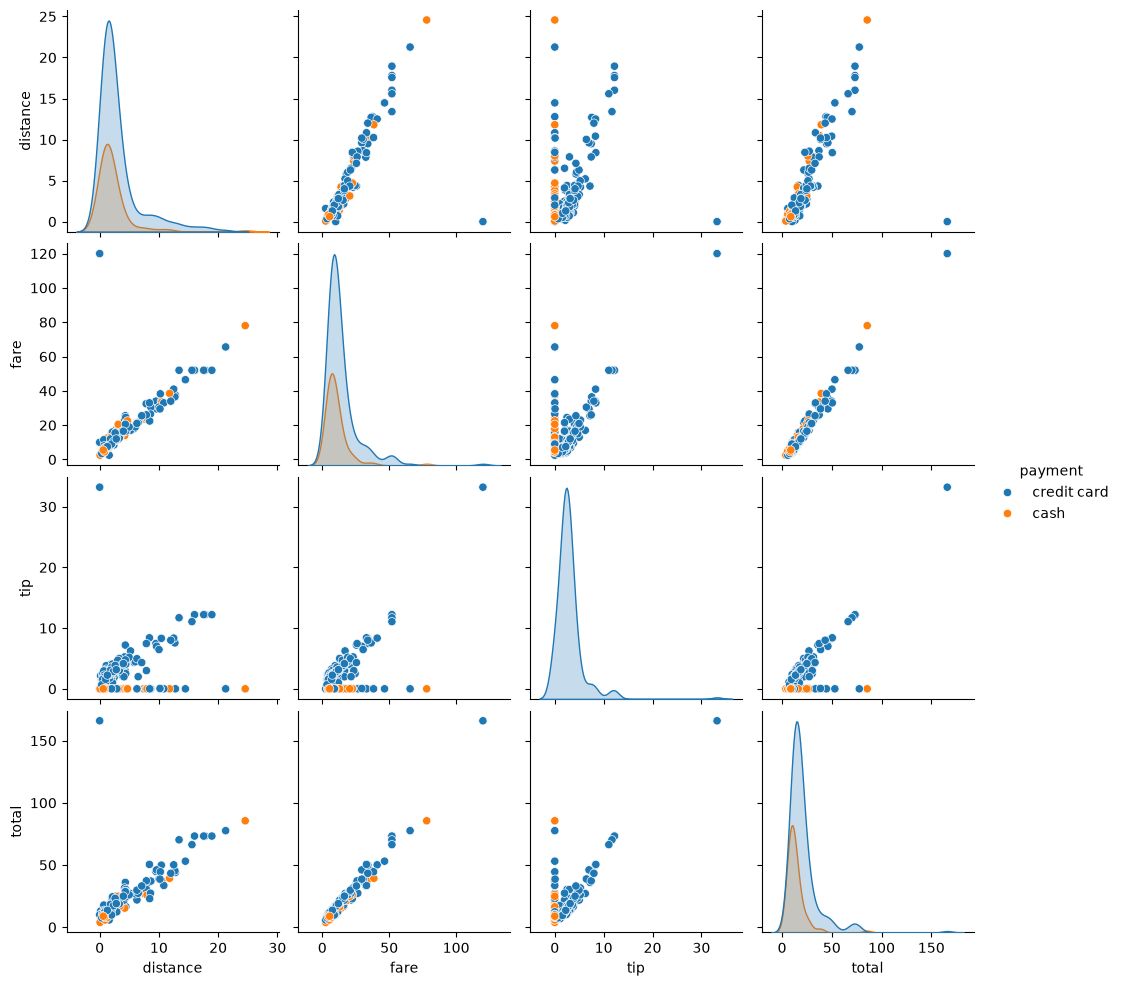

In [19]:
sample_df = df.sample(300, random_state=42)

sns.pairplot(
    sample_df,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='payment'
)

plt.show()

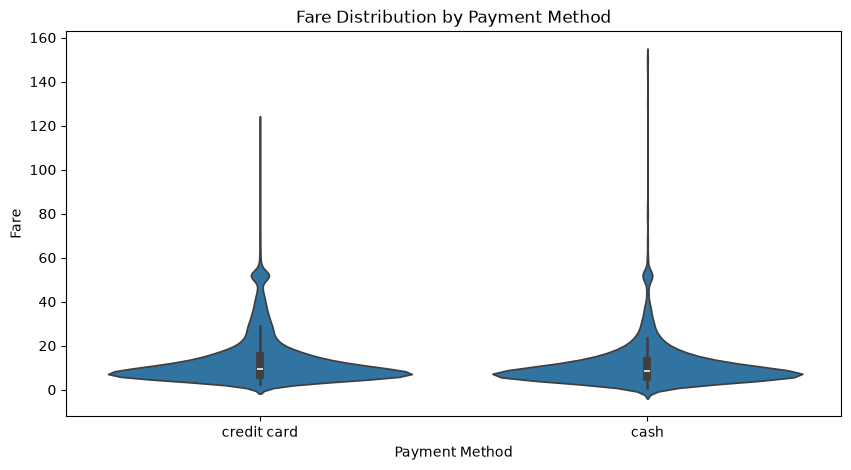

In [20]:
plt.figure(figsize=(10,5))

sns.violinplot(
    data=df,
    x='payment',
    y='fare'
)

plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare")

plt.show()